In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
df=pd.read_csv('/content/Advertising Budget and Sales.csv')
df.head()

,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [ ]:
df = df.drop(columns=['Radio Ad Budget ($)', 'Newspaper Ad Budget ($)', 'Unnamed: 0'])
display(df.head())

,TV Ad Budget ($),Sales ($)
0,230.1,22.1
1,44.5,10.4
2,17.2,9.3
3,151.5,18.5
4,180.8,12.9


In [ ]:
df.shape

(200, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   TV Ad Budget ($)  200 non-null    float64
 1   Sales ($)         200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


In [ ]:
df.describe()

,TV Ad Budget ($),Sales ($)
count,200.000000,200.000000
mean,147.042500,14.022500
std,85.854236,5.217457
min,0.700000,1.600000
25%,74.375000,10.375000
50%,149.750000,12.900000
75%,218.825000,17.400000
max,296.400000,27.000000


In [ ]:
df.isnull().sum()

,0
TV Ad Budget ($),0
Sales ($),0


In [ ]:
#duplicates
print(df.duplicated().sum())
# Remove duplicates if any
df.drop_duplicates(inplace=True)

0


<Axes: ylabel='TV Ad Budget ($)'>

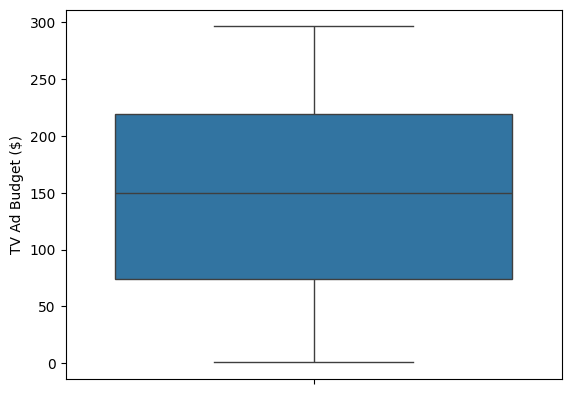

In [ ]:
#Outlier detection
sns.boxplot(df['TV Ad Budget ($)'])

In [ ]:
#dependent&independent variable
x=df['TV Ad Budget ($)'] #df.iloc[:,0].values
y=df['Sales ($)'] #df.iloc[:,1].values

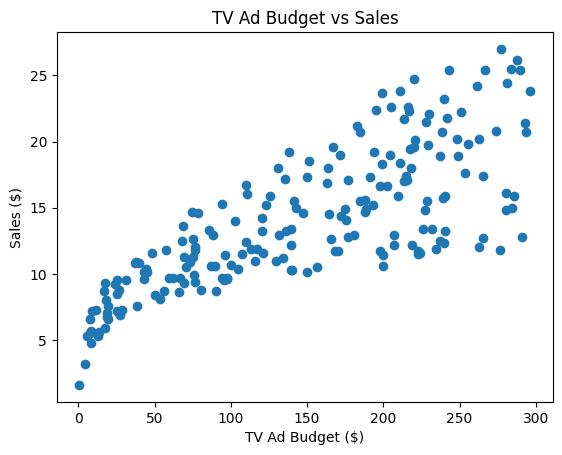

In [ ]:
#rln b/w dependent&non-dependent is Linear/non-linear
plt.scatter(x,y)
plt.xlabel('TV Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('TV Ad Budget vs Sales')
plt.show()

In [ ]:
# Split the dataset into training and testing sets
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
model=LinearRegression()
model.fit(x_train.values.reshape(-1,1),y_train)

LinearRegression()

In [ ]:
print(f"Number of instances for training: {len(x_train)}")
print(f"Number of instances for testing: {len(x_test)}")

Number of instances for training: 160
Number of instances for testing: 40


In [ ]:
polynomial_features=PolynomialFeatures(degree=2)

In [ ]:
x_poly=polynomial_features.fit_transform(x.to_frame())

In [ ]:
#Model Building
lr_model=LinearRegression()
lr_model.fit(x_poly,y)

LinearRegression()

In [ ]:
#Model Training
x_train_poly = polynomial_features.transform(x_train.to_frame())
model.fit(x_train_poly, y_train)
print("Model Trained Successfully")

Model Trained Successfully


In [ ]:
#Predictions
y_pred=lr_model.predict(x_poly)
df=pd.DataFrame({'Actual':y,'Predicted':y_pred})
print(df)

     Actual  Predicted
0      22.1  17.966832
1      10.4   8.971867
2       9.3   7.250838
3      18.5  14.733383
4      12.9  16.037630
..      ...        ...
195     7.6   8.583765
196     9.7  11.842998
197    12.8  15.875113
198    25.5  19.683819
199    13.4  18.038071

[200 rows x 2 columns]


In [ ]:
#Evaluation metrics on training dataset
print("Model Evaluation Metrics on Training Dataset:")
y_train_pred = model.predict(x_train_poly)
mae = mean_absolute_error(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_train_pred)
print("  Mean Absolute Error (MAE):", mae)
print("  Mean Squared Error (MSE):", mse)
print("  Root MSE (RMSE):", rmse)
print("  R2 Score:", r2)

Model Evaluation Metrics on Training Dataset:
  Mean Absolute Error (MAE): 2.581738968060615
  Mean Squared Error (MSE): 10.274328680728399
  Root MSE (RMSE): 3.205359368421644
  R2 Score: 0.6017654790678126


In [ ]:
#Evaluation metrics on testing dataset
print("Model Evaluation Metrics on Testing Dataset:")
x_test_poly = polynomial_features.transform(x_test.to_frame())
y_test_pred = model.predict(x_test_poly)
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)
print("  Mean Absolute Error (MAE):", mae)
print("  Mean Squared Error (MSE):", mse)
print("  Root MSE (RMSE):", rmse)
print("  R2 Score: ", r2)

Model Evaluation Metrics on Testing Dataset:
  Mean Absolute Error (MAE): 2.563679083792365
  Mean Squared Error (MSE): 10.685507926293752
  Root MSE (RMSE): 3.268869518089358
  R2 Score:  0.6604481473780814


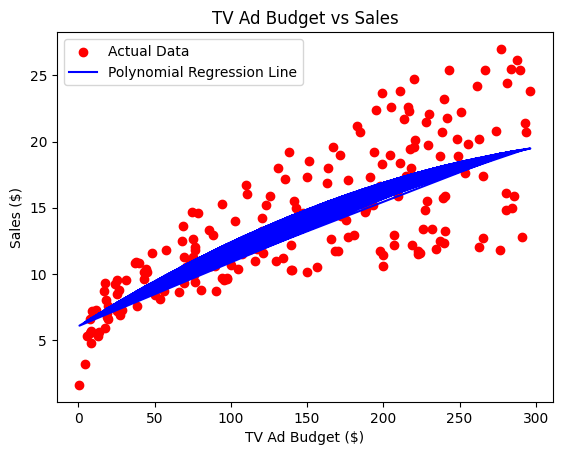

In [ ]:
plt.scatter(x,y,color='red',label='Actual Data')
plt.plot(x,model.predict(polynomial_features.transform(x.to_frame())),color='blue',label='Polynomial Regression Line')
plt.legend()
plt.xlabel('TV Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('TV Ad Budget vs Sales')
plt.show()